In [1]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

profile_df = pd.read_csv("../../data/processed/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)
profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,5.286957,2.0,-0.475000,0.0,0.251724,0.328571,0.410714,0.0,0.0,0.0
1,10002013,1,0,0,0,0,0,0,0,0,...,4.634783,0.5,0.025000,0.0,0.389655,0.714286,0.375000,0.0,0.0,0.0
2,10002155,1,0,0,0,0,0,0,0,0,...,5.661538,10.5,0.125000,0.0,0.341379,0.500000,0.384058,0.0,0.0,0.0
3,10004457,0,0,0,1,0,0,0,0,0,...,0.000000,0.0,-0.075000,0.0,0.396552,0.357143,0.300000,0.0,0.0,0.0
4,10007058,1,0,0,0,0,0,0,0,0,...,4.582609,1.5,-0.315789,0.0,0.220000,1.416667,0.375000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0


In [2]:
#correletion
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

#print the feautures with correlation higer than 0.8
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.8)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('unique_antibiotics_count', 'sensitive_microorganism_ratio')]

In [3]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count', 'max_wbc count'])

# Identifica colonne categoriche da escludere
categorical_cols = ['subject_id', 'gender', 'ACS_acute_ischemic', 'Chronic_ischemic', 
                   'Heart_failure', 'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy', 
                   'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest', 
                   'Arrhythmias_or_conduction']

# Seleziona solo le colonne numeriche per il clustering
numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]
numeric_df = profile_df[numeric_cols]

# Verifica le colonne numeriche selezionate
print("Colonne numeriche per clustering:")
print(numeric_cols)
print(f"\nNumero di features: {len(numeric_cols)}")

Colonne numeriche per clustering:
['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_platelet count', 'max_white blood cells', 'abnormal_lab_event_ratio', 'resistant_microorganism_ratio', 'intermediate_microorganism_ratio', 'sensitive_microorganism_ratio']

Numero di features: 24


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(numeric_df)


/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/utils/kneed.py:156: YellowbrickWarning: No 'knee' or 'elbow point' detected This could be due to bad clustering, no actual clusters being formed etc.
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/cluster/elbow.py:374: YellowbrickWarning: No 'knee' or 'elbow' point detected, pass `locate_elbow=False` to remove the warning
  warnings.warn(warning_message, YellowbrickWarning)


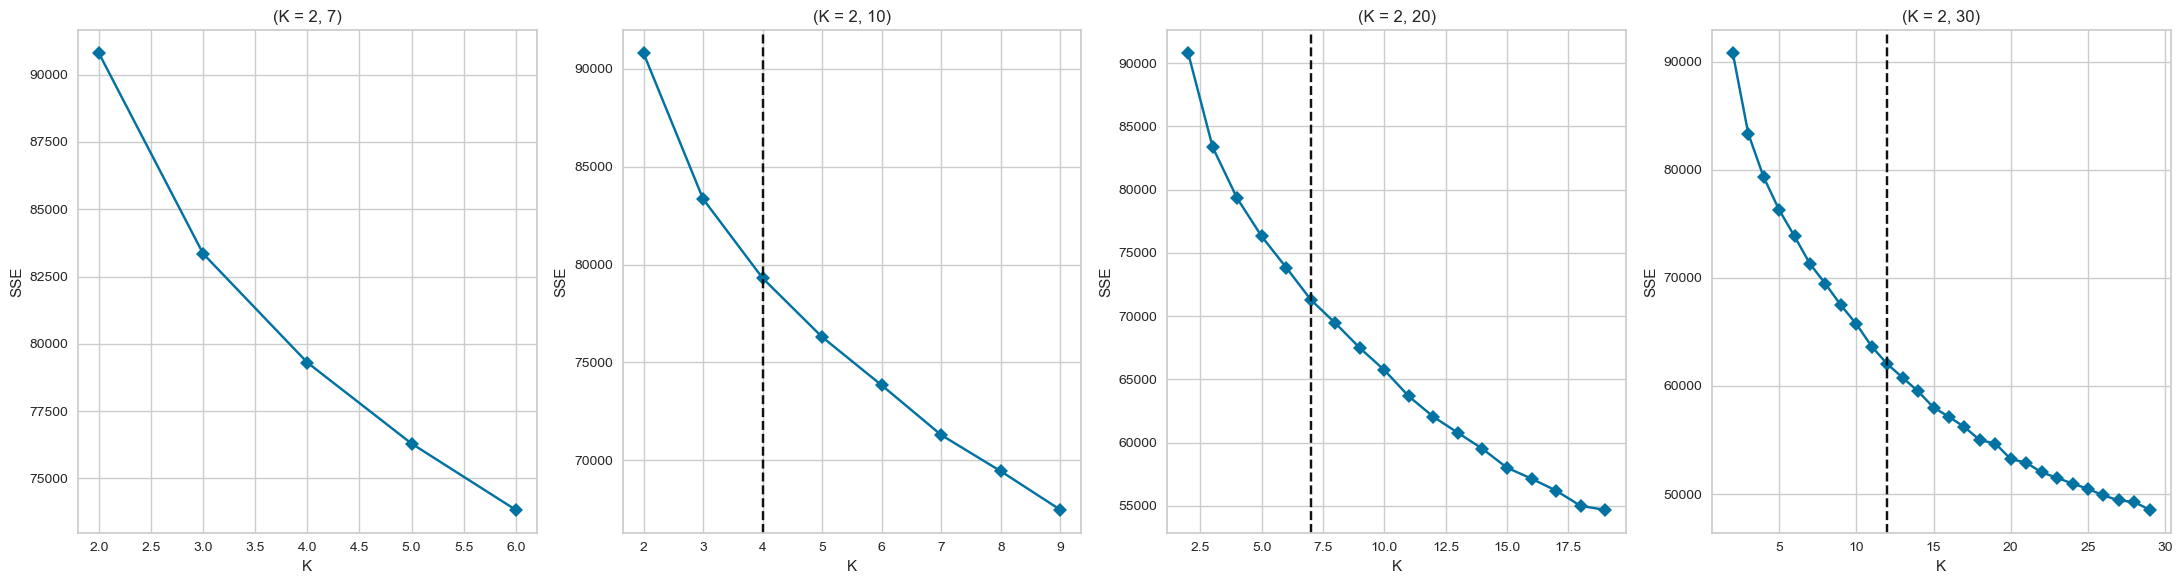

K suggeriti dal metodo elbow: [np.int64(4), np.int64(7), np.int64(12)]


In [5]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

random_state = 42  # fisso
# Range multipli da testare (2→10, 2→20, 2→30)
k_start = 2
k_max_list = [7,10, 20, 30]

model = KMeans(n_init=10, max_iter=100, random_state=random_state)

fig, axs = plt.subplots(1, len(k_max_list), figsize=(22, 6))

best_Ks = []

for i, k_max in enumerate(k_max_list):
    
    visualizer = KElbowVisualizer(
        model,
        k=(k_start, k_max),
        metric='distortion',    # SSE (inertia)
        timings=False,
        ax=axs[i]
    )

    visualizer.fit(X)  
    
    axs[i].set_title(f'(K = {k_start}, {k_max})')
    axs[i].set_ylabel('SSE')
    axs[i].set_xlabel('K')
    
    elbow_k = visualizer.elbow_value_
    elbow_score = visualizer.elbow_score_

    if elbow_k is not None and elbow_k not in best_Ks:
        best_Ks.append(elbow_k)

plt.tight_layout()
plt.show()
plt.style.use("default") 


print("K suggeriti dal metodo elbow:", best_Ks)


In [6]:
#ciclo di valutazione delle metriche per k da 2 a 10
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn import metrics

results = []

# Valuta k da 2 a 11
for k in range(2, 12):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100, random_state=random_state)
    kmeans.fit(X)
    labels = kmeans.labels_
    
    sse = kmeans.inertia_
    silhouette = silhouette_score(X, labels)
    db = metrics.davies_bouldin_score(X, labels)
    
    results.append([k, sse, silhouette, db])

results_df = pd.DataFrame(results, columns=["K", "SSE", "Silhouette", "DB_score"])
print(results_df)


    K           SSE  Silhouette  DB_score
0   2  90793.893065    0.301608  2.289134
1   3  83348.596506    0.199820  2.271887
2   4  79305.033283    0.093983  2.467984
3   5  76295.815350    0.091432  2.299857
4   6  73833.644447    0.092308  2.395304
5   7  71293.254570    0.073336  2.258025
6   8  69443.358859    0.059176  2.240275
7   9  67472.527086    0.078716  2.168037
8  10  65725.009699    0.065630  2.070883
9  11  63643.270608    0.080226  1.965694


Internal validation metrics did not identify a single optimal number of clusters. Silhouette scores were generally low, indicating weakly separated but continuous patient profiles. Based on a trade-off between compactness and interpretability, k = 3 was selected for further analysis.

In [7]:
from sklearn.cluster import KMeans

k = 3
kmeans = KMeans(n_clusters=k, n_init=10, max_iter=100, random_state=random_state)
kmeans.fit(X)

labels = kmeans.labels_

np.unique(labels, return_counts=True)


(array([0, 1, 2], dtype=int32), array([2761,  356, 1266]))

/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_17949/725894234.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_values, y=value_counts, palette="tab10")


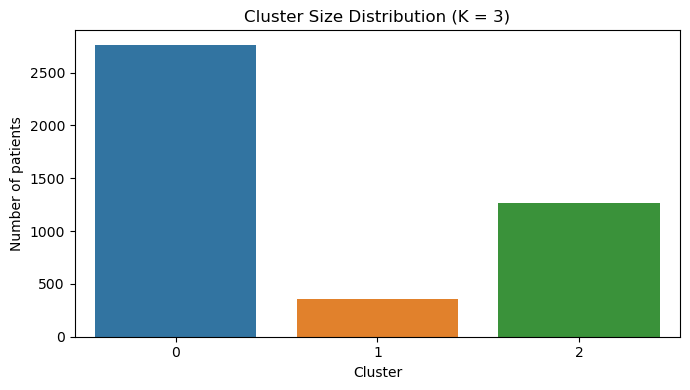

Cluster 0: 2761 pazienti
Cluster 1: 356 pazienti
Cluster 2: 1266 pazienti


In [8]:
# Distribuzione dei pazienti nei cluster
unique_values, value_counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(7, 4))
sns.barplot(x=unique_values, y=value_counts, palette="tab10")

plt.xlabel("Cluster")
plt.ylabel("Number of patients")
plt.title("Cluster Size Distribution (K = 3)")
plt.tight_layout()
plt.show()

# Stampa numeri
for c, n in zip(unique_values, value_counts):
    print(f"Cluster {c}: {n} pazienti")



In [9]:
centroids_scaled = pd.DataFrame(kmeans.cluster_centers_, columns=numeric_df.columns)
centroids_scaled.index.name = "cluster"
display(centroids_scaled)

,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,-0.211687,-0.127689,-0.433043,-0.367976,-0.271759,-0.159919,-0.353481,-0.385916,-0.155547,-0.366748,...,-0.129044,-0.252663,-0.263384,0.231106,-0.168722,-0.213748,-0.450369,-0.221019,-0.136806,-0.269771
1,0.313491,0.202018,1.155410,1.148403,2.361576,0.466380,0.487988,0.650900,0.238504,0.421568,...,0.215224,0.476379,0.299779,-0.229704,0.361172,0.545141,0.668574,2.503514,1.547517,3.136253
2,0.373050,0.221391,0.618685,0.478912,-0.071560,0.217321,0.632900,0.657780,0.271825,0.680463,...,0.220632,0.416543,0.489517,-0.438894,0.266058,0.312450,0.793216,-0.221971,-0.136806,-0.293559


In [10]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers = pd.DataFrame(centers, columns=numeric_df.columns)
centers.index.name = "cluster"
display(centers)


,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,1.027899,68.901630,74.539493,0.610507,0.039493,2.683696,2.106763,0.582126,0.590399,0.912681,...,0.758944,2.170323,2.063859,-0.058859,0.317966,0.724878,0.296400,1.811594e-04,9.714451e-17,0.006884
1,1.224719,72.014045,299.910112,3.078652,1.606742,4.707865,4.462105,0.970711,0.710206,2.756421,...,6.054259,4.778437,5.398876,-0.278576,0.519785,1.524967,0.467593,5.188202e-01,1.941792e-01,0.879526
2,1.247040,72.196922,223.759274,1.988950,0.158642,3.902920,4.867727,0.973290,0.720337,3.361935,...,6.137437,4.564378,6.522494,-0.378318,0.483559,1.279643,0.486663,1.526557e-16,2.081668e-17,0.000789


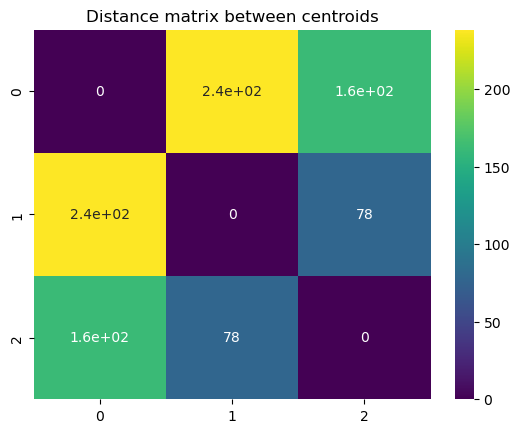

In [11]:
centers_np = centers.to_numpy() 

dist_matrix = np.zeros((k, k))
for i in range(k):
    for j in range(k):
        dist_matrix[i, j] = np.linalg.norm(centers_np[i] - centers_np[j])

sns.heatmap(dist_matrix, annot=True, cmap="viridis")
plt.title("Distance matrix between centroids")
plt.show()


Coppie manuali usate: [('age', 'lab_event_count'), ('age', 'microbio_test_count'), ('lab_event_count', 'unique_procedures_count'), ('max_glucose', 'abnormal_lab_event_ratio')]


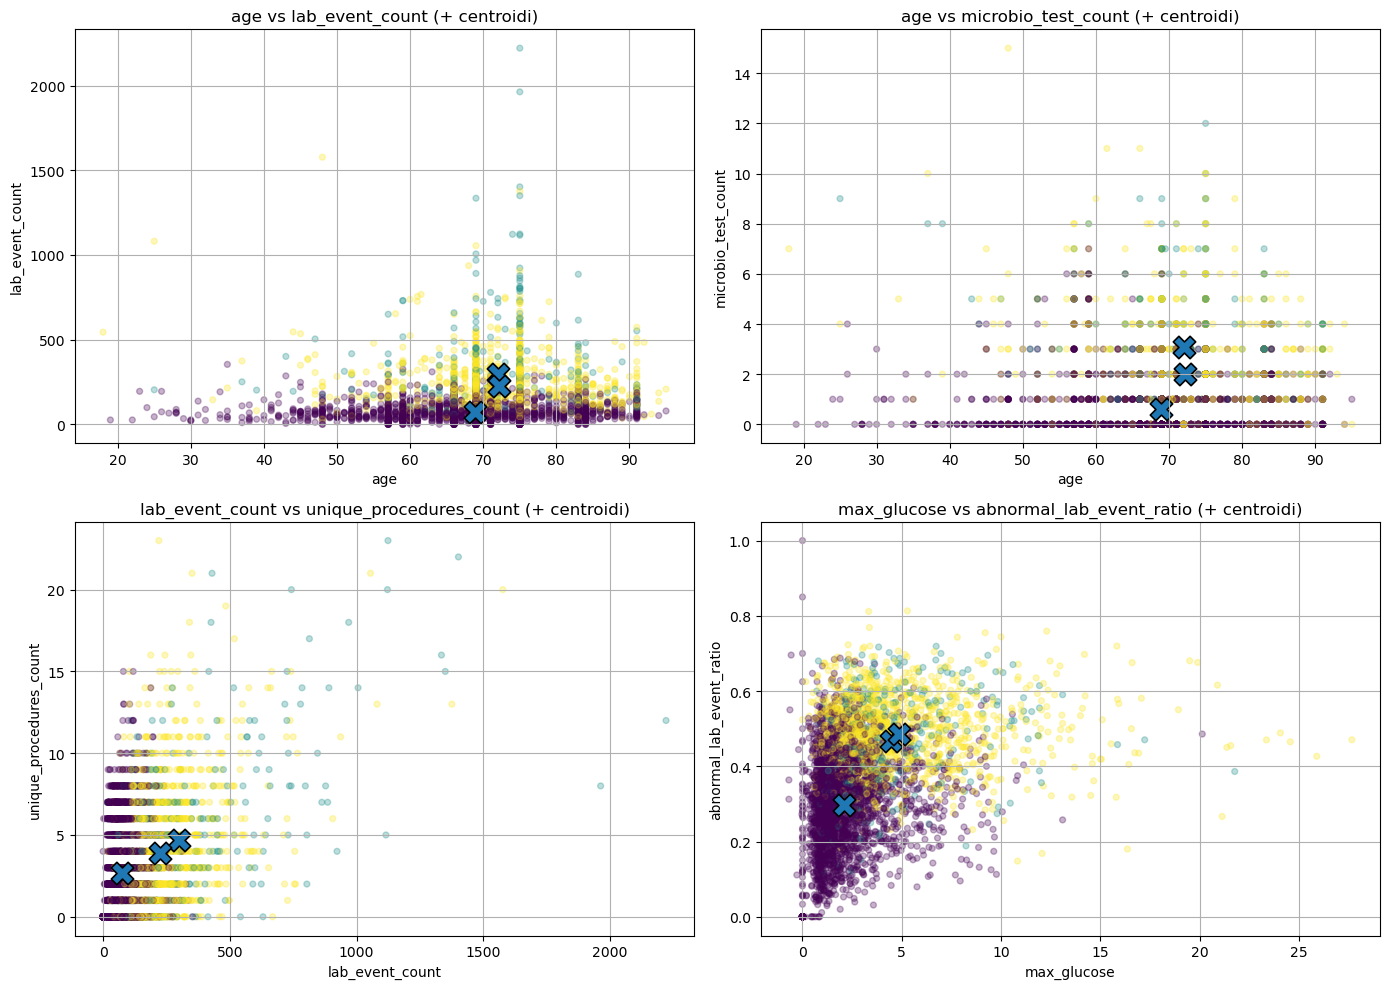

Coppie extra usate: [('max_creatinine', 'max_urea nitrogen'), ('max_creatinine', 'max_potassium'), ('max_inr(pt)', 'max_ptt'), ('max_inr(pt)', 'max_platelet count')]


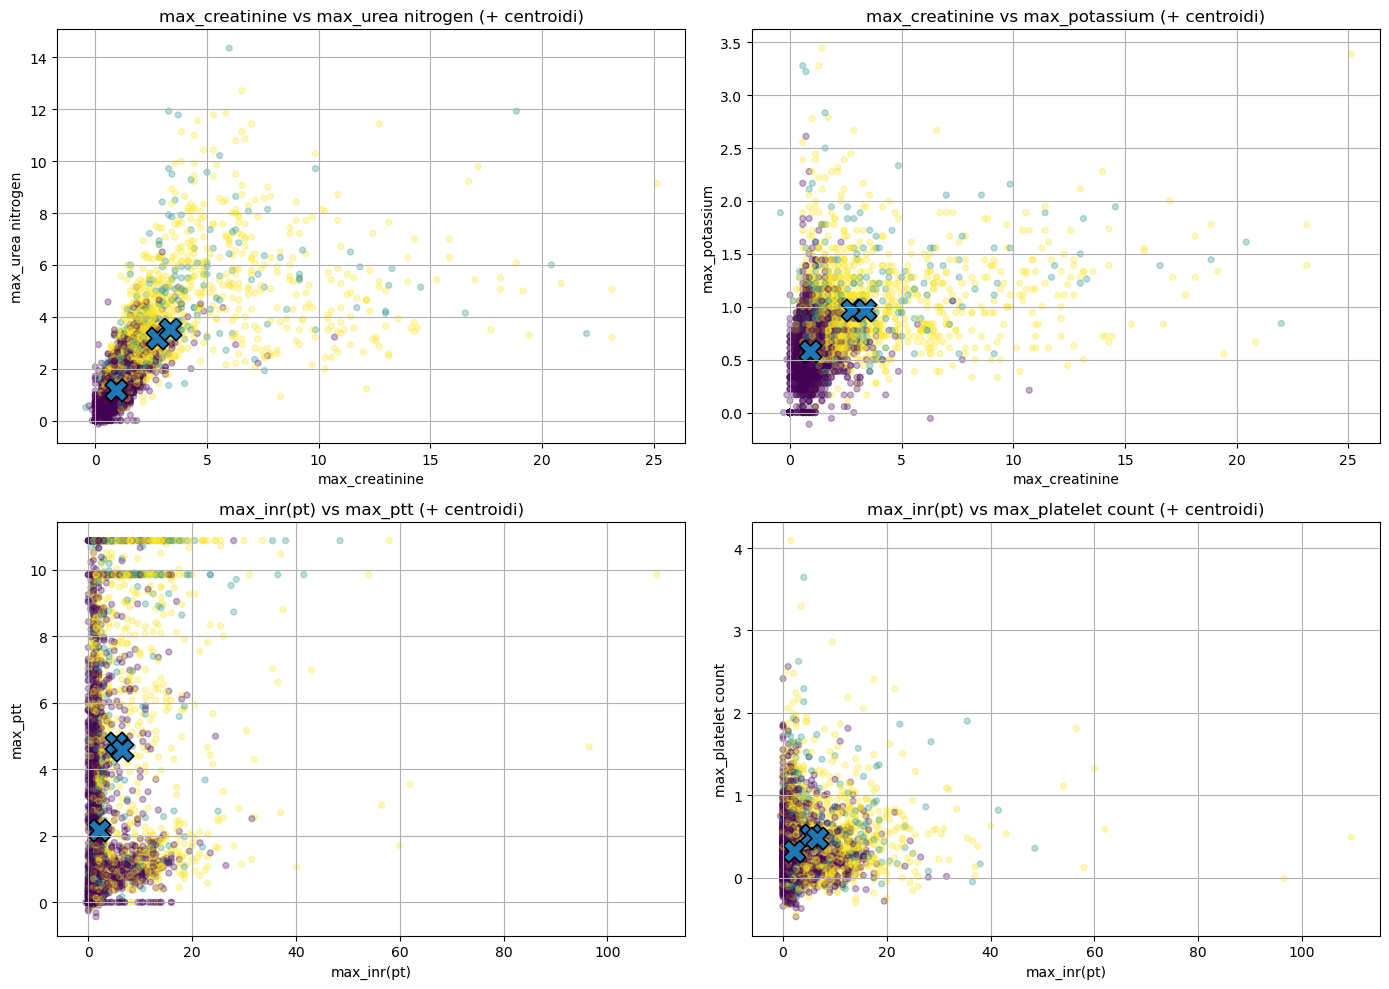

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def scatter_with_centroids(ax, xcol, ycol, df, labels, kmeans, scaler, numeric_cols,
                           s=20, alpha=0.35, centroid_size=260):

    xi = numeric_cols.index(xcol)
    yi = numeric_cols.index(ycol)

    x = df[xcol].values
    y = df[ycol].values

    cent = kmeans.cluster_centers_
    cx = cent[:, xi] * scaler.scale_[xi] + scaler.mean_[xi]
    cy = cent[:, yi] * scaler.scale_[yi] + scaler.mean_[yi]

    sc = ax.scatter(x, y, c=labels, s=s, alpha=alpha)
    ax.scatter(cx, cy, marker="X", s=centroid_size, edgecolor="black", linewidth=1.2)

    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.grid(True)
    return sc

pairs = [
    ("age", "lab_event_count"),
    ("age", "microbio_test_count"),
    ("lab_event_count", "unique_procedures_count"),
    ("max_glucose", "abnormal_lab_event_ratio"),  # ratio (come nel tuo dataset)
]

# tieni solo coppie valide
pairs = [(a,b) for a,b in pairs if a in numeric_df.columns and b in numeric_df.columns]
print("Coppie manuali usate:", pairs)

n = len(pairs)
cols = 2
rows = int(np.ceil(n / cols))

fig, axs = plt.subplots(rows, cols, figsize=(14, 5*rows))
axs = np.array(axs).reshape(-1)

for idx, (xcol, ycol) in enumerate(pairs):
    scatter_with_centroids(
        axs[idx], xcol, ycol,
        df=numeric_df, labels=labels,
        kmeans=kmeans, scaler=scaler, numeric_cols=numeric_cols,
        s=18, alpha=0.30, centroid_size=260
    )
    axs[idx].set_title(f"{xcol} vs {ycol} (+ centroidi)")

for j in range(idx+1, len(axs)):
    axs[j].axis("off")

plt.tight_layout()
plt.show()

pairs_extra = [
    ("max_creatinine", "max_urea nitrogen"),
    ("max_creatinine", "max_potassium"),
    ("max_inr(pt)", "max_ptt"),
    ("max_inr(pt)", "max_platelet count"),
]
pairs_extra = [(a,b) for a,b in pairs_extra if a in numeric_df.columns and b in numeric_df.columns]
print("Coppie extra usate:", pairs_extra)

n = len(pairs_extra)
cols = 2
rows = int(np.ceil(n / cols))

fig, axs = plt.subplots(rows, cols, figsize=(14, 5*rows))
axs = np.array(axs).reshape(-1)

for idx, (xcol, ycol) in enumerate(pairs_extra):
    scatter_with_centroids(
        axs[idx], xcol, ycol,
        df=numeric_df, labels=labels,
        kmeans=kmeans, scaler=scaler, numeric_cols=numeric_cols,
        s=18, alpha=0.30, centroid_size=260
    )
    axs[idx].set_title(f"{xcol} vs {ycol} (+ centroidi)")

for j in range(idx+1, len(axs)):
    axs[j].axis("off")

plt.tight_layout()
plt.show()



/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_17949/1157595535.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_values, y=value_counts, palette="tab10")


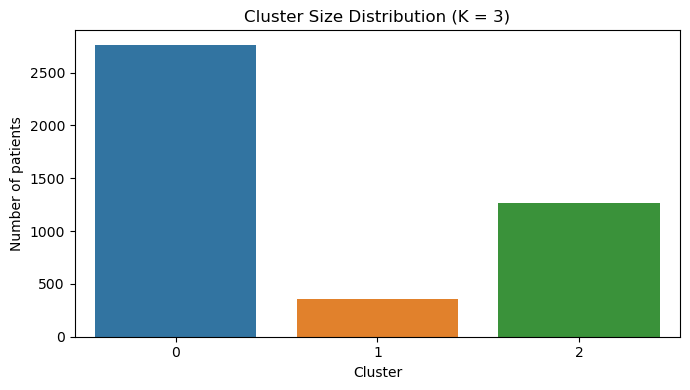

Cluster 0: 2761 pazienti
Cluster 1: 356 pazienti
Cluster 2: 1266 pazienti


In [13]:
# Distribuzione dei pazienti nei cluster
unique_values, value_counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(7, 4))
sns.barplot(x=unique_values, y=value_counts, palette="tab10")

plt.xlabel("Cluster")
plt.ylabel("Number of patients")
plt.title("Cluster Size Distribution (K = 3)")
plt.tight_layout()
plt.show()

# Stampa numeri
for c, n in zip(unique_values, value_counts):
    print(f"Cluster {c}: {n} pazienti")


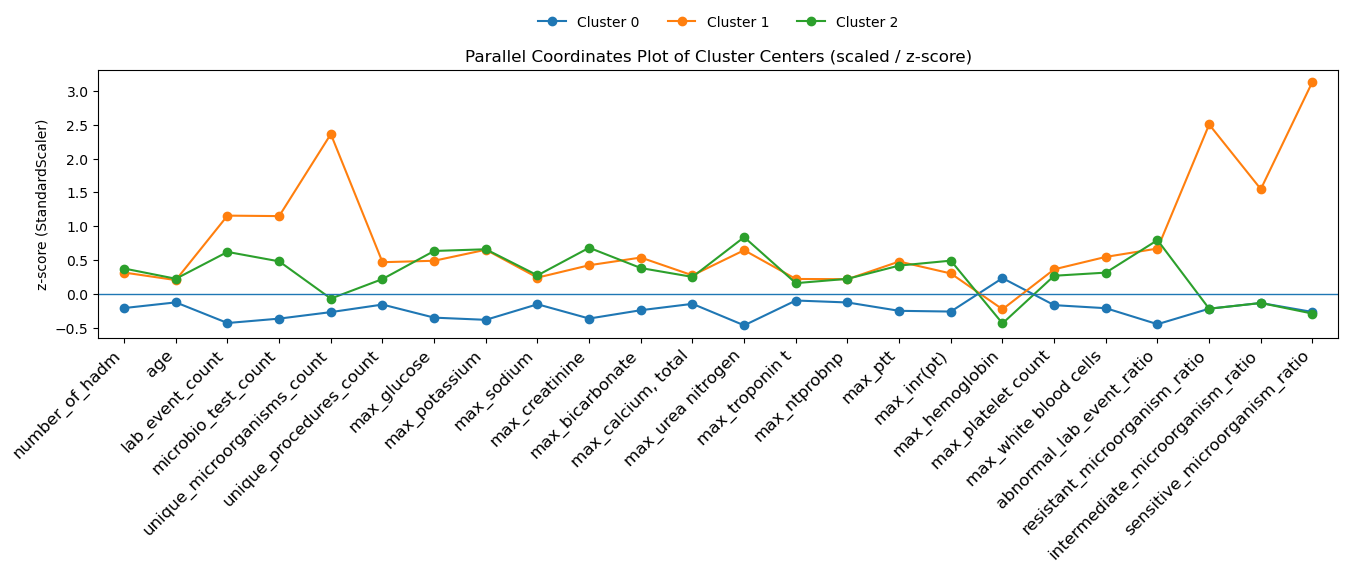

In [18]:
# Parallel Coordinates sensato (confronto tra feature) usando centroidi SCALATI (z-score)

import numpy as np
import matplotlib.pyplot as plt

centers_scaled = kmeans.cluster_centers_   # shape (k, p)
N = centers_scaled.shape[1]
x = np.arange(N)

plt.figure(figsize=(16, 4))
for i in range(centers_scaled.shape[0]):
    plt.plot(x, centers_scaled[i], marker='o', label=f'Cluster {i}')

plt.axhline(0, linewidth=1)  # baseline: media globale
plt.xticks(x, numeric_df.columns, fontsize=12, rotation=45, ha='right')
plt.xlim(-0.5, N - 0.5)

plt.ylabel("z-score (StandardScaler)")
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.25),
           ncol=centers_scaled.shape[0], frameon=False)

plt.subplots_adjust(top=0.78)
plt.title("Parallel Coordinates Plot of Cluster Centers (scaled / z-score)")
plt.show()


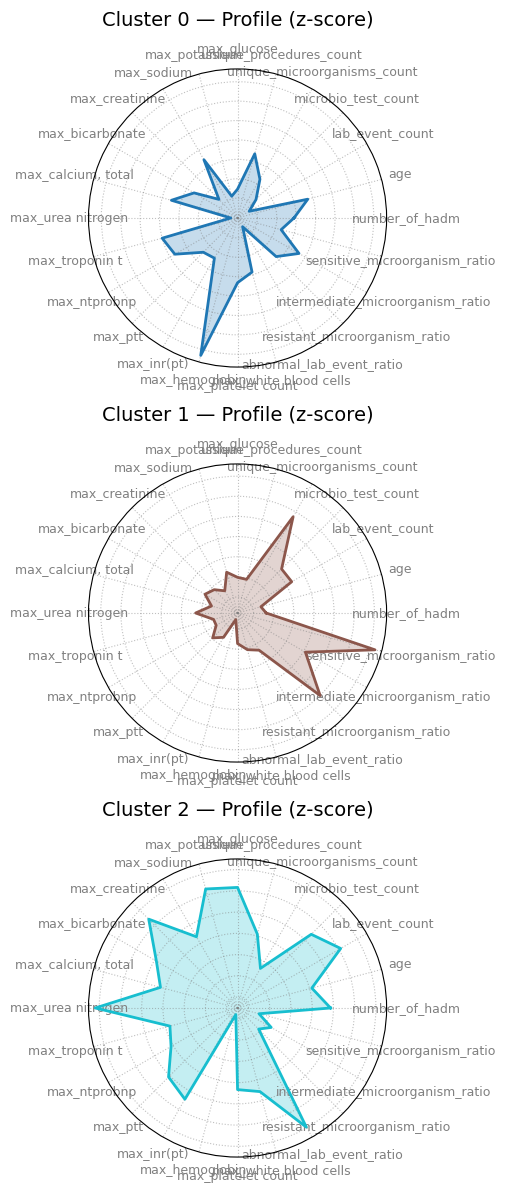

In [19]:
from math import pi
import numpy as np
import matplotlib.pyplot as plt

centers_np = kmeans.cluster_centers_  # <-- SCALATI (z-score)

N = centers_np.shape[1]
features_labels = numeric_df.columns.tolist()
colors = plt.cm.tab10(np.linspace(0, 1, centers_np.shape[0]))

plt.figure(figsize=(12, 12))

for cluster_id in range(centers_np.shape[0]):
    values = centers_np[cluster_id].tolist()
    values += values[:1]

    angles = [n / float(N) * 2*pi for n in range(N)]
    angles += angles[:1]

    ax = plt.subplot(centers_np.shape[0], 1, cluster_id + 1, polar=True)

    ax.plot(angles, values, linewidth=2, color=colors[cluster_id])
    ax.fill(angles, values, alpha=0.25, color=colors[cluster_id])

    plt.xticks(angles[:-1], features_labels, size=9, color="grey")
    ax.grid(color="grey", linestyle="dotted", alpha=0.5)
    ax.set_yticklabels([])
    ax.set_title(f"Cluster {cluster_id} — Profile (z-score)", size=14, y=1.12)

plt.tight_layout()
plt.show()


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_17949/2495088612.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_17949/2495088612.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_17949/2495088612.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")


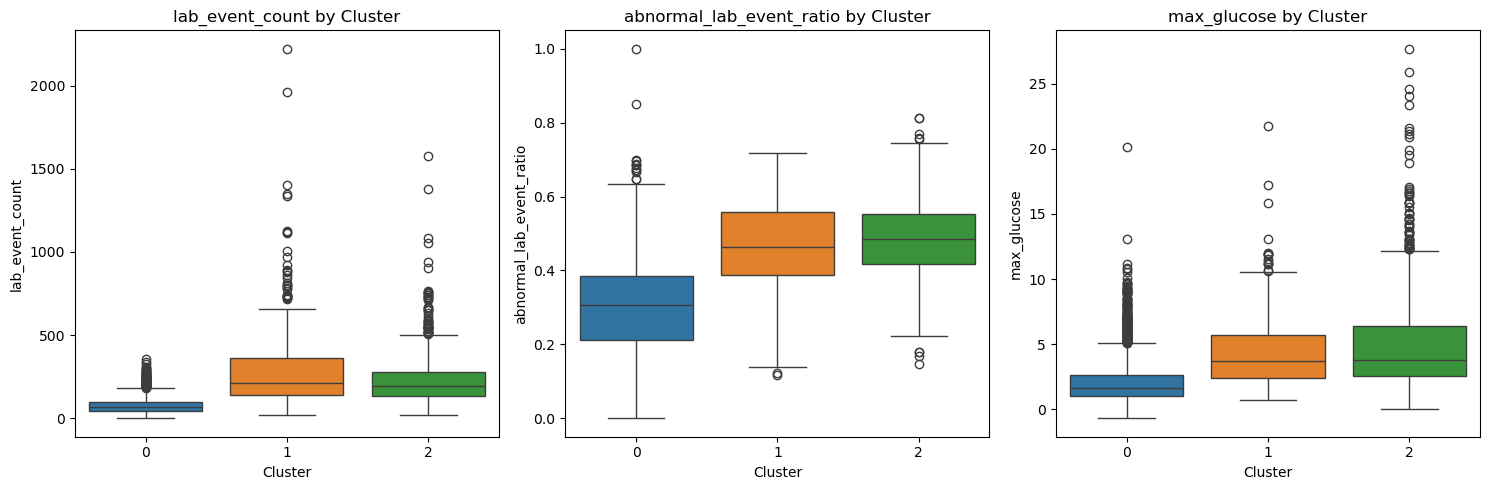

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Creiamo un DataFrame con i dati originali e il cluster assegnato
df_box = numeric_df.copy()
df_box["Cluster"] = labels

vars_to_plot = [
    "lab_event_count",
    "abnormal_lab_event_ratio",
    "max_glucose",
]

plt.figure(figsize=(15, 5))

for i, var in enumerate(vars_to_plot, 1):
    plt.subplot(1, len(vars_to_plot), i)
    sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
    plt.title(f"{var} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(var)

plt.tight_layout()
plt.show()


I boxplot confermano con grande chiarezza la separazione tra i tre cluster individuati da K-Means. Per tutte e tre le variabili cliniche considerate, lab_event_count, abnormal_lab_event_ratio e max_glucose, emerge una struttura ordinata e coerente:

- **Cluster 0** presenta valori bassi in tutte le variabili, indicando pazienti con un profilo clinico semplice e un numero molto ridotto di esami eseguiti.

- **Cluster 1** mostra valori intermedi, con un’attività diagnostica maggiore e un livello di anomalie superiore rispetto al cluster precedente.

- **Cluster 2** evidenzia le mediane e i massimi più elevati, configurandosi come il gruppo di pazienti più complesso e clinicamente instabile, caratterizzato da un numero elevato di esami, molte anomalie di laboratorio e valori glicemici più alti.


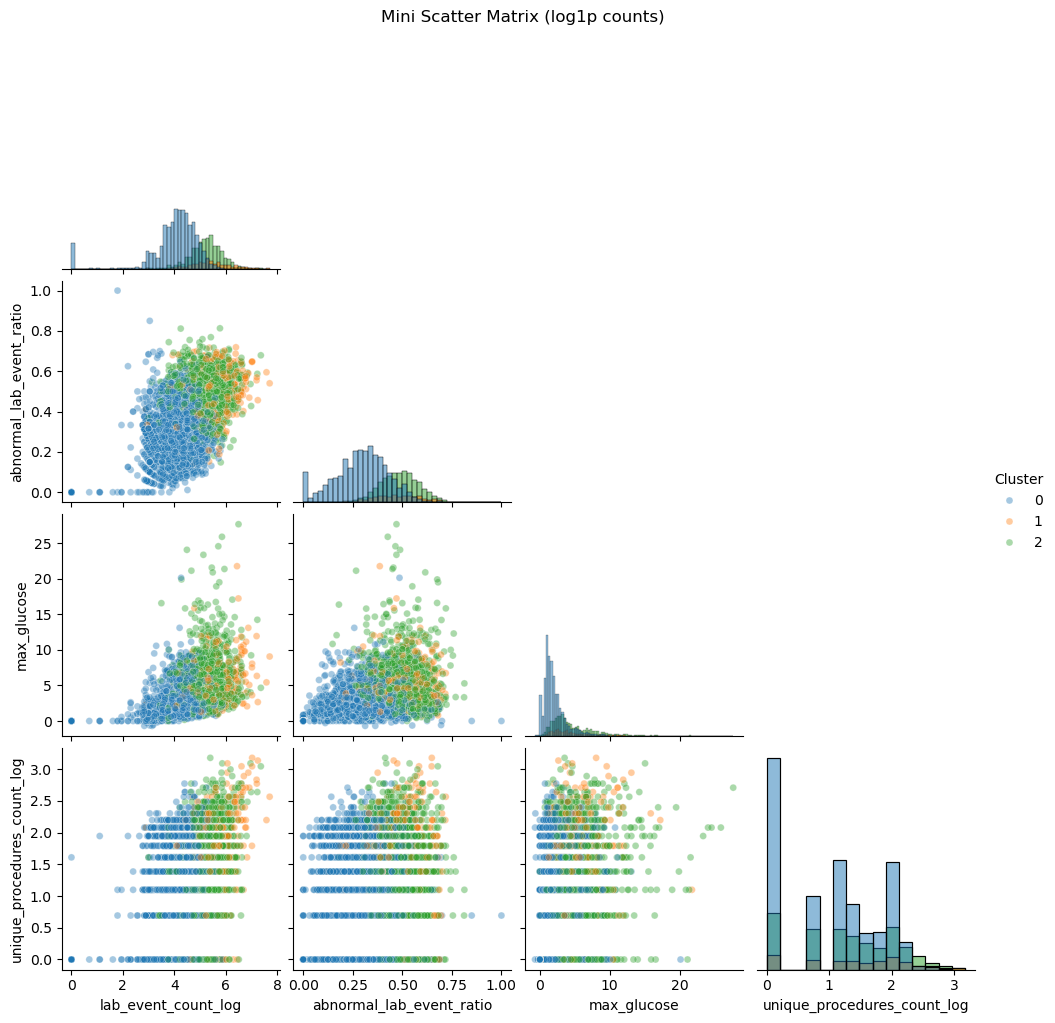

In [20]:
df_scatter = numeric_df.copy()
df_scatter["Cluster"] = labels

df_scatter["lab_event_count_log"] = np.log1p(df_scatter["lab_event_count"])
df_scatter["unique_procedures_count_log"] = np.log1p(df_scatter["unique_procedures_count"])

vars_scatter = [
    "lab_event_count_log",
    "abnormal_lab_event_ratio",
    "max_glucose",
    "unique_procedures_count_log"
]

sns.pairplot(
    df_scatter[vars_scatter + ["Cluster"]],
    hue="Cluster",
    palette="tab10",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 25}
)

plt.suptitle("Mini Scatter Matrix (log1p counts)", y=1.02)
plt.show()


### Mini Scatter Matrix
La scatter matrix costruita sulle quattro variabili clinicamente più informative (*lab_event_count*, *abnormal_lab_event_ratio*, *max_glucose* e
*unique_procedures_count*) conferma in modo visivo la separazione tra i tre cluster.

In particolare:

- **Cluster 0** (blu) si concentra sistematicamente nelle regioni a valori bassi: pochissimi esami, poche anomalie, glicemie più contenute e poche procedure.
Rappresenta il gruppo di pazienti a bassa complessità.

- **Cluster 1** (arancione) occupa la fascia intermedia in tutte le proiezioni, con un numero maggiore di esami e anomalie rispetto al cluster precedente ma senza raggiungere i livelli più elevati.
È il gruppo con complessità moderata.

- **Cluster 2** (verde) domina le regioni con valori più alti, mostrando molte anomalie, un numero elevato di esami, glicemia più alta e più procedure.
È il cluster dei pazienti più complessi e clinicamente instabili.


spiegazione del grafico per capire: Nei grafici diagonali della scatter matrix compaiono le curve di densità (KDE) delle
singole variabili per ciascun cluster. È normale che il cluster 2 presenti curve più
basse e più larghe: questo non indica valori inferiori, ma riflette il fatto che il
cluster contiene molti meno pazienti (353 contro oltre 2800 del cluster 0) e i valori
sono più dispersi. Le curve KDE sono infatti normalizzate: l’area totale è sempre 1,
indipendentemente dal numero di osservazioni. Per questo i cluster numerosi e con
valori concentrati producono curve più alte, mentre quelli meno frequenti o più
variabili mostrano curve più schiacciate. 

